# Siamese vs. Standard GIN Training: Graph Classification Comparison

All conditions share the **same dataset, same graph architecture, same sort readout, and same classifier MLP**.
Only the encoder-training recipe differs, isolating specific confounds in the
Siamese-vs-Standard comparison (node-repulsion objective, two-stage freezing, compute budget).

| Condition | Encoder objective | Procedure | Total steps |
|---|---|---|---|
| **Siamese** | Node repulsion (clean + permuted graph) | Pretrain → freeze → train classifier | 1 000 + 2 000 |
| **Standard-2k** | Cross-entropy | Joint end-to-end | 2 000 |
| **Standard-3k** | Cross-entropy | Joint end-to-end, budget-matched to Siamese | 3 000 |
| **Standard-Frozen** | Cross-entropy | Pretrain jointly → freeze encoder → train fresh classifier | 1 000 + 2 000 |
| **Random-Frozen** | None (random init) | Freeze at init → train classifier | 0 + 2 000 |

`Standard-3k` isolates whether Siamese's edge comes from more gradient updates.
`Standard-Frozen` isolates whether it comes from the two-stage freeze-then-train
procedure, independent of the node-repulsion objective.
`Random-Frozen` isolates how much of
the accuracy/margin is attributable to actually training the encoder at all,
versus a fixed random projection plus a trained classifier alone (a
random-features / reservoir-computing baseline).

**Dataset** follows `gin_depth_graph_classification`: N=1000 train pairs/class,
200 test pairs/class, 200 noisy-iso pairs per $k$ for the by-$k$ sweep.

Every condition is trained and evaluated over **m=5 random seeds** per depth,
and all figures/tables report mean ± std.

## 0. Setup


In [1]:
%%capture
!pip install torch_geometric

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINConv
from torch_geometric.data import Data, Batch as PyGBatch
import numpy as np
import random
import warnings
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

# ── Node feature choice ──────────────────────────────────────────────────────
# 'degree'       : node feature = degree of the *input* graph (recomputed from
#                  the perturbed graph at inference time, not the clean graph).
# 'all_ones'     : constant all-ones feature vector, invariant to perturbation.
# 'random_fixed' : a random vector drawn once per node when the clean graph is
#                  sampled; held fixed (acts as a node id) under edge perturbation.
FEATURE_TYPE = 'all_ones'   # 'degree' | 'all_ones' | 'random_fixed'

# ── Graph / model hyperparameters (shared) ────────────────────────────────────
N_NODES    = 30
ER_PROB    = 0.3
FEAT_DIM   = 1
HIDDEN_DIM = 64
EMBED_DIM  = 32
GRAPH_DIM  = 64
N_CLASSES  = 3
DEPTH_VALUES = [3, 4, 5, 6]

# ── Siamese hyperparameters ───────────────────────────────────────────────────
GIN_MARGIN = 1.0
GIN_STEPS  = 1000
CLS_STEPS  = 2000

# ── Standard hyperparameters ──────────────────────────────────────────────────
STD_STEPS = 2000

# ── Ablation config ───────────────────────────────────────────────────────────
STD_STEPS_MATCHED     = GIN_STEPS + CLS_STEPS   # 3000: Standard-3k, budget-matched to Siamese
FROZEN_PRETRAIN_STEPS = GIN_STEPS               # 1000: Standard-Frozen's joint CE pretrain phase
SEEDS                 = [42,43,44,45,46]    # m=5 repeats per (condition, depth)

# ── Shared optimizer settings ─────────────────────────────────────────────────
BATCH_SIZE = 64
LR         = 1e-3
WD         = 1e-4

# ── Dataset (same as gin_depth_graph_classification) ─────────────────────────
N_TRAIN       = 1000
N_TEST        = 200
N_TEST_PER_K  = 200
NOISY_K_TRAIN = [1, 2, 3]
NOISY_K_TEST  = [1, 2, 3]

LABEL_ISO   = 0
LABEL_NOISY = 1
LABEL_IRR   = 2
CLASS_NAMES = ['Isomorphic', 'Noisy Iso', 'Irrelevant']

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 130})
CMAP_L  = cm.viridis
NORM_L  = plt.Normalize(vmin=min(DEPTH_VALUES), vmax=max(DEPTH_VALUES))
COLOR_L = {L: CMAP_L(NORM_L(L)) for L in DEPTH_VALUES}

# ── Frozen-encoder pretrain length: 0 (Random-Frozen) vs. FROZEN_PRETRAIN_STEPS ──
# (Standard-Frozen), isolating how much of the accuracy/margin comes from
# actually training the encoder vs. a fixed random projection.
FROZEN_STEPS_SWEEP = {
    'Random-Frozen':   0,
    'Standard-Frozen': FROZEN_PRETRAIN_STEPS,
}

# ── Five training conditions under comparison ─────────────────────────────────
CONDITIONS = ['Siamese', 'Standard-2k', 'Standard-3k',
              'Standard-Frozen', 'Random-Frozen']
COND_STYLE = {
    'Siamese':         {'color': 'steelblue',        'ls': '-',  'marker': 's'},
    'Standard-2k':     {'color': 'tomato',           'ls': '--', 'marker': 'o'},
    'Standard-3k':     {'color': 'darkorange',       'ls': '-.', 'marker': '^'},
    'Standard-Frozen': {'color': 'seagreen',         'ls': ':',  'marker': 'D'},
    'Random-Frozen':   {'color': 'gray',             'ls': (0, (1, 1)), 'marker': 'x'},
}


Device: cuda


## 1. Graph Generation


In [3]:
def compute_features(A, feat_dim, feature_type, rng):
    n = A.shape[0]
    if feature_type == 'degree':
        degree = (A.sum(1, keepdims=True) / n).astype(np.float32)
        if feat_dim > 1:
            degree = np.concatenate(
                [degree, np.zeros((n, feat_dim - 1), dtype=np.float32)], axis=1)
        return degree
    elif feature_type == 'all_ones':
        return np.ones((n, feat_dim), dtype=np.float32)
    elif feature_type == 'random_fixed':
        return rng.randn(n, feat_dim).astype(np.float32)
    else:
        raise ValueError(f'Unknown FEATURE_TYPE: {feature_type}')


def sample_er_graph(n=N_NODES, p=ER_PROB, feat_dim=FEAT_DIM, seed=None,
                    feature_type=FEATURE_TYPE):
    rng    = np.random.RandomState(seed) if seed is not None else np.random
    A      = np.zeros((n, n), dtype=np.float32)
    for i in range(n):
        for j in range(i + 1, n):
            if rng.rand() < p:
                A[i, j] = A[j, i] = 1.0
    feats = compute_features(A, feat_dim, feature_type, rng)
    return A, feats


def permute_graph(A, feats, seed=None):
    rng  = np.random.RandomState(seed) if seed is not None else np.random
    perm = rng.permutation(A.shape[0])
    return A[np.ix_(perm, perm)], feats[perm].copy()


def perturb_graph(A, feats, k, seed=None, feature_type=FEATURE_TYPE):
    rng        = np.random.RandomState(seed) if seed is not None else np.random
    n          = A.shape[0]
    Ap         = A.copy()
    rows, cols = np.triu_indices(n, k=1)
    for idx in rng.choice(len(rows), min(k, len(rows)), replace=False):
        r, c = rows[idx], cols[idx]
        Ap[r, c] = Ap[c, r] = 1.0 - Ap[r, c]
    if feature_type == 'degree':
        # recompute degree from the perturbed (input) graph, not the clean one
        fp       = feats.copy()
        fp[:, 0] = Ap.sum(1) / n
    else:
        # all_ones / random_fixed features are node-level and structure-independent,
        # so they stay unchanged under edge perturbation
        fp = feats.copy()
    return Ap, fp


def to_pyg(A, feats, device=DEVICE):
    ei = torch.tensor(np.array(np.where(A > 0)), dtype=torch.long)
    x  = torch.tensor(feats, dtype=torch.float32)
    return Data(x=x, edge_index=ei, num_nodes=A.shape[0]).to(device)


def make_iso_pair(seed):
    A, f   = sample_er_graph(seed=seed)
    Ap, fp = permute_graph(A, f, seed=seed + 1)
    return A, f, Ap, fp

def make_noisy_pair(seed, k):
    A, f   = sample_er_graph(seed=seed)
    Ap, fp = perturb_graph(A, f, k, seed=seed + 1)
    return A, f, Ap, fp

def make_irr_pair(seed):
    A1, f1 = sample_er_graph(seed=seed)
    A2, f2 = sample_er_graph(seed=seed + 100000)
    return A1, f1, A2, f2


print(f'Graph: {N_NODES} nodes, ER p={ER_PROB}')


Graph: 30 nodes, ER p=0.3


## 2. Models

Both schemes share `GINEncoder` and `SortReadout`.
- **Siamese / the frozen-encoder family** (`Standard-Frozen`, `Random-Frozen`): frozen `GINEncoder` + `GraphPairClassifier` (readout + MLP trained on pre-computed embeddings).
- **Standard-2k / Standard-3k**: `GINEndToEnd` wraps all three and trains jointly.

In [4]:
# ── Shared components ─────────────────────────────────────────────────────────
class GINEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers):
        super().__init__()
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        for i in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(dims[i], dims[i+1]), nn.ReLU(),
                nn.Linear(dims[i+1], dims[i+1]),
            )
            self.convs.append(GINConv(mlp, train_eps=True))
            self.bns.append(nn.BatchNorm1d(dims[i+1]))

    def forward(self, data):
        x, ei = data.x, data.edge_index
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, ei)))
        return F.normalize(x, p=2, dim=1)


class SortReadout(nn.Module):
    """Supports single-graph (n, d) and batched (B, n, d) inputs."""
    def __init__(self, n_nodes, in_dim, out_dim):
        super().__init__()
        self.rho = nn.Linear(in_dim, in_dim)
        self.a   = nn.Parameter(torch.ones(in_dim))
        self.b   = nn.Linear(n_nodes * in_dim, out_dim)

    def forward(self, x):
        h = self.rho(x) * self.a
        if x.dim() == 2:                        # single graph (n, d)
            h, _ = torch.sort(h, dim=0)
            return self.b(h.flatten().unsqueeze(0)).squeeze(0)
        else:                                   # batched (B, n, d)
            h, _ = torch.sort(h, dim=1)
            return self.b(h.flatten(start_dim=1))


def _make_mlp():
    return nn.Sequential(
        nn.Linear(2 * GRAPH_DIM, GRAPH_DIM), nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(GRAPH_DIM, GRAPH_DIM // 2), nn.ReLU(),
        nn.Linear(GRAPH_DIM // 2, N_CLASSES),
    )


# ── Siamese: readout + classifier on top of frozen GIN ────────────────────────
class GraphPairClassifier(nn.Module):
    """Takes pre-computed node embeddings (frozen GIN output)."""
    def __init__(self):
        super().__init__()
        self.readout = SortReadout(N_NODES, EMBED_DIM, GRAPH_DIM)
        self.mlp     = _make_mlp()

    def forward(self, emb1, emb2):              # single pair: (n, d)
        g1   = self.readout(emb1)
        g2   = self.readout(emb2)
        feat = torch.cat([torch.abs(g1 - g2), g1 * g2])
        return self.mlp(feat.unsqueeze(0)).squeeze(0)

    def forward_batch(self, emb1, emb2):        # batched: (B, n, d)
        g1   = self.readout(emb1)               # (B, graph_dim)
        g2   = self.readout(emb2)
        feat = torch.cat([torch.abs(g1 - g2), g1 * g2], dim=1)
        return self.mlp(feat)                   # (B, N_CLASSES)


# ── Standard: encoder + readout + classifier trained jointly ──────────────────
class GINEndToEnd(nn.Module):
    def __init__(self, num_layers):
        super().__init__()
        self.encoder = GINEncoder(FEAT_DIM, HIDDEN_DIM, EMBED_DIM, num_layers)
        self.readout = SortReadout(N_NODES, EMBED_DIM, GRAPH_DIM)
        self.mlp     = _make_mlp()

    def forward(self, data1, data2):            # single-pair (for eval)
        g1   = self.readout(self.encoder(data1))
        g2   = self.readout(self.encoder(data2))
        feat = torch.cat([torch.abs(g1 - g2), g1 * g2])
        return self.mlp(feat.unsqueeze(0)).squeeze(0)

    def forward_batch(self, batch1, batch2, B): # batched (for training)
        emb1 = self.encoder(batch1).view(B, N_NODES, EMBED_DIM)
        emb2 = self.encoder(batch2).view(B, N_NODES, EMBED_DIM)
        feat = torch.cat([torch.abs(self.readout(emb1) - self.readout(emb2)),
                          self.readout(emb1) * self.readout(emb2)], dim=1)
        return self.mlp(feat)


# ── Utilities ─────────────────────────────────────────────────────────────────
def compute_margin(emb):
    with torch.no_grad():
        d    = torch.cdist(emb, emb, p=2)
        mask = ~torch.eye(d.shape[0], dtype=torch.bool, device=d.device)
        return d[mask].min().item()


def repulsion_loss(emb, margin):
    """Push every node's embedding away from a randomly-paired *distinct* node
    in the same graph, up to `margin`. Directly targets the node-level margin
    measured by `measure_gamma`, rather than relying on a permutation-matched
    'positive' pair (which, since GIN is exactly permutation-equivariant, is
    both structurally guaranteed already and, if misaligned by index, ends up
    pulling random distinct nodes together instead)."""
    n       = emb.shape[0]
    shift   = torch.randint(1, n, (n,), device=emb.device)
    neg_idx = (torch.arange(n, device=emb.device) + shift) % n
    d_neg   = (emb - emb[neg_idx]).norm(p=2, dim=1)
    return F.relu(margin - d_neg).mean()


def measure_gamma(encoder, n_graphs=50):
    g_list = []
    with torch.no_grad():
        for s in range(n_graphs):
            A_t, f_t = sample_er_graph(seed=s + 9000)
            g_list.append(compute_margin(encoder(to_pyg(A_t, f_t))))
    return float(np.mean(g_list))


print('All model classes defined.')

All model classes defined.


## 3. Dataset

Raw graph pairs are built once with fixed seeds (matching `gin_depth_graph_classification`),
shared across all five conditions.
- **Standard-2k / Standard-3k** use raw PyG pairs directly.
- **Siamese / the frozen-encoder family** call `embed_dataset` with their (frozen) encoder after training.

In [5]:
def build_raw_dataset(n_per_class, k_range, seed_offset=0):
    data = []
    for i in range(n_per_class):
        s = seed_offset + i
        A1, f1, A2, f2 = make_iso_pair(s * 3)
        data.append((A1, f1, A2, f2, LABEL_ISO, 0))
        k = k_range[i % len(k_range)]
        A1, f1, A2, f2 = make_noisy_pair(s * 3 + 1, k)
        data.append((A1, f1, A2, f2, LABEL_NOISY, k))
        A1, f1, A2, f2 = make_irr_pair(s * 3 + 2)
        data.append((A1, f1, A2, f2, LABEL_IRR, 0))
    return data


def build_raw_by_k(n_per_k, k_values, seed_offset=500000):
    by_k = defaultdict(list)
    for k in k_values:
        for i in range(n_per_k):
            s = seed_offset + k * 10000 + i
            A1, f1, A2, f2 = make_noisy_pair(s, k)
            by_k[k].append((A1, f1, A2, f2, LABEL_NOISY, k))
    return by_k


def to_pyg_pairs(raw):
    """Pre-convert raw numpy pairs to PyG on CPU."""
    return [(to_pyg(A1, f1).cpu(), to_pyg(A2, f2).cpu(), lbl, k)
            for A1, f1, A2, f2, lbl, k in raw]


@torch.no_grad()
def embed_dataset(gin, raw):
    """Siamese: embed raw pairs with frozen GIN, store on CPU."""
    return [(gin(to_pyg(A1, f1)).cpu(), gin(to_pyg(A2, f2)).cpu(), lbl, k)
            for A1, f1, A2, f2, lbl, k in raw]


print('Building raw datasets (fixed seeds, shared across all conditions)...')
raw_train = build_raw_dataset(N_TRAIN, NOISY_K_TRAIN, seed_offset=0)
raw_test  = build_raw_dataset(N_TEST,  NOISY_K_TEST,  seed_offset=200000)
raw_by_k  = build_raw_by_k(N_TEST_PER_K, NOISY_K_TEST, seed_offset=500000)

# Standard pre-converts to PyG once
pyg_train = to_pyg_pairs(raw_train)
pyg_test  = to_pyg_pairs(raw_test)
pyg_by_k  = {k: to_pyg_pairs(v) for k, v in raw_by_k.items()}

print(f'Train: {len(raw_train)} pairs  |  Test: {len(raw_test)} pairs')
print(f'By-k:  {N_TEST_PER_K} noisy pairs per k={NOISY_K_TEST}')


Building raw datasets (fixed seeds, shared across all conditions)...
Train: 3000 pairs  |  Test: 600 pairs
By-k:  200 noisy pairs per k=[1, 2, 3]


## 4. Training Functions

One function per condition's encoder-training recipe:
- `train_gin_siamese` + `train_classifier` — Siamese's two stages (node-repulsion pretrain, then frozen classifier training).
- `train_standard` (parameterized by `steps`) — covers both `Standard-2k` (`steps=STD_STEPS`) and `Standard-3k` (`steps=STD_STEPS_MATCHED`).
- `train_standard_frozen` (parameterized by `pretrain_steps`) — joint cross-entropy pretrain, then freeze the encoder; drives `Standard-Frozen` via `FROZEN_STEPS_SWEEP` (reuses `train_classifier` for its second stage).
- `train_random_frozen` — no pretraining at all; freezes the encoder at random init for `Random-Frozen`, the `pretrain_steps=0` point of that same sweep.

In [6]:
# ── Siamese training ──────────────────────────────────────────────────────────
def train_gin_siamese(num_layers, seed=42):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = GINEncoder(FEAT_DIM, HIDDEN_DIM, EMBED_DIM, num_layers).to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=5e-4)
    for _ in range(GIN_STEPS):
        model.train()
        A, f   = sample_er_graph()
        Ap, fp = permute_graph(A, f)
        # Self-supervised node-separation objective: push each node's embedding
        # away from a random *distinct* node's embedding, evaluated on both the
        # clean graph and a relabeled (permuted) copy so each step covers two
        # different sets of original-node pairs.
        loss = (repulsion_loss(model(to_pyg(A, f)),   GIN_MARGIN) +
                repulsion_loss(model(to_pyg(Ap, fp)),  GIN_MARGIN))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


# ── Random-Frozen: no encoder training at all, frozen at random init ─────────
def train_random_frozen(num_layers, seed=42):
    """Randomly-initialized GINEncoder, frozen immediately (0 pretrain steps).
    Same frozen-encoder contract as train_gin_siamese / train_standard_frozen,
    so it plugs into embed_dataset / train_classifier / evaluate_siamese
    unchanged. Isolates how much of the accuracy/margin comes from actually
    training the encoder vs. a fixed random projection plus a trained
    classifier alone (a random-features / reservoir-computing baseline)."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = GINEncoder(FEAT_DIM, HIDDEN_DIM, EMBED_DIM, num_layers).to(DEVICE)
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


def train_classifier(emb_train, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    clf   = GraphPairClassifier().to(DEVICE)
    opt   = torch.optim.Adam(clf.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CLS_STEPS)

    # Pre-stack all embeddings on GPU once — avoids 64 × .to(DEVICE) per step
    # Memory: 3000 pairs × 2 × (30 × 32) floats ≈ 23 MB, trivial on any GPU
    embs1  = torch.stack([e[0] for e in emb_train]).to(DEVICE)  # (N, n, d)
    embs2  = torch.stack([e[1] for e in emb_train]).to(DEVICE)
    labels = torch.tensor([e[2] for e in emb_train],
                          dtype=torch.long, device=DEVICE)
    n      = len(emb_train)
    losses = []

    for _ in range(CLS_STEPS):
        clf.train()
        idx    = torch.randint(n, (BATCH_SIZE,), device=DEVICE)
        logits = clf.forward_batch(embs1[idx], embs2[idx])
        loss   = F.cross_entropy(logits, labels[idx])
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(clf.parameters(), 1.0)
        opt.step(); sched.step()
        losses.append(loss.item())

    clf.eval()
    return clf, losses


# ── Standard training (steps parameterized: covers Standard-2k and Standard-3k) ─
def train_standard(num_layers, train_data, steps=STD_STEPS, seed=42):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model  = GINEndToEnd(num_layers).to(DEVICE)
    opt    = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    n      = len(train_data)
    losses = []
    for _ in range(steps):
        model.train()
        idx   = np.random.choice(n, BATCH_SIZE, replace=True)
        items = [train_data[i] for i in idx]
        b1    = PyGBatch.from_data_list([it[0] for it in items]).to(DEVICE)
        b2    = PyGBatch.from_data_list([it[1] for it in items]).to(DEVICE)
        lbls  = torch.tensor([it[2] for it in items],
                             dtype=torch.long, device=DEVICE)
        loss  = F.cross_entropy(model.forward_batch(b1, b2, len(idx)), lbls)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        losses.append(loss.item())
    model.eval()
    return model, losses


# ── Standard-Frozen: joint CE pretrain, then freeze the encoder ──────────────
def train_standard_frozen(num_layers, train_data, pretrain_steps=GIN_STEPS, seed=42):
    """Joint CE training for `pretrain_steps`, then freeze the encoder and
    discard the readout/MLP head. Returns a frozen GINEncoder with the same
    contract as `train_gin_siamese`, so it plugs into `embed_dataset` /
    `train_classifier` / `evaluate_siamese` unchanged."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model  = GINEndToEnd(num_layers).to(DEVICE)
    opt    = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=pretrain_steps)
    n      = len(train_data)
    for _ in range(pretrain_steps):
        model.train()
        idx   = np.random.choice(n, BATCH_SIZE, replace=True)
        items = [train_data[i] for i in idx]
        b1    = PyGBatch.from_data_list([it[0] for it in items]).to(DEVICE)
        b2    = PyGBatch.from_data_list([it[1] for it in items]).to(DEVICE)
        lbls  = torch.tensor([it[2] for it in items],
                             dtype=torch.long, device=DEVICE)
        loss  = F.cross_entropy(model.forward_batch(b1, b2, len(idx)), lbls)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()

    encoder = model.encoder
    encoder.eval()
    for p in encoder.parameters():
        p.requires_grad_(False)
    return encoder


print('Training functions defined.')

Training functions defined.


## 5. Evaluation Functions & Condition Dispatch

`evaluate_siamese`/`evaluate_standard` share the same `(acc, per_class, preds, labels)`
contract; `eval_by_k_*` compute the noisy-iso robustness curve. `train_condition` /
`evaluate_condition` dispatch on a condition name so the main loop (§6) doesn't need
to special-case each recipe.


In [7]:
@torch.no_grad()
def evaluate_siamese(gin, clf, pyg_data):
    gin.eval(); clf.eval()
    preds, labels = [], []
    for d1, d2, lbl, _ in pyg_data:
        e1 = gin(d1.to(DEVICE))
        e2 = gin(d2.to(DEVICE))
        preds.append(clf(e1, e2).argmax().item())
        labels.append(lbl)
    preds, labels = np.array(preds), np.array(labels)
    acc       = (preds == labels).mean()
    per_class = {c: float((preds[labels == c] == c).mean()) for c in range(N_CLASSES)}
    return acc, per_class, preds, labels


@torch.no_grad()
def evaluate_standard(model, pyg_data):
    model.eval()
    preds, labels = [], []
    for d1, d2, lbl, _ in pyg_data:
        preds.append(model(d1.to(DEVICE), d2.to(DEVICE)).argmax().item())
        labels.append(lbl)
    preds, labels = np.array(preds), np.array(labels)
    acc       = (preds == labels).mean()
    per_class = {c: float((preds[labels == c] == c).mean()) for c in range(N_CLASSES)}
    return acc, per_class, preds, labels


@torch.no_grad()
def eval_by_k_siamese(gin, clf, by_k):
    gin.eval(); clf.eval()
    return {
        k: sum(clf(gin(d1.to(DEVICE)), gin(d2.to(DEVICE))).argmax().item() == LABEL_NOISY
               for d1, d2, _, __ in data) / len(data)
        for k, data in by_k.items()
    }


@torch.no_grad()
def eval_by_k_standard(model, by_k):
    model.eval()
    return {
        k: sum(model(d1.to(DEVICE), d2.to(DEVICE)).argmax().item() == LABEL_NOISY
               for d1, d2, _, __ in data) / len(data)
        for k, data in by_k.items()
    }


# ── Condition dispatch ────────────────────────────────────────────────────────
def train_condition(cond, L, seed):
    """Train one (condition, depth, seed); returns a uniform fit dict."""
    if cond == 'Siamese':
        gin       = train_gin_siamese(L, seed=seed)
        emb_train = embed_dataset(gin, raw_train)
        clf, _    = train_classifier(emb_train, seed=seed)
        return {'kind': 'siamese', 'encoder': gin, 'clf': clf, 'gamma': measure_gamma(gin)}

    if cond == 'Standard-2k':
        model, _ = train_standard(L, pyg_train, steps=STD_STEPS, seed=seed)
        return {'kind': 'standard', 'model': model, 'gamma': measure_gamma(model.encoder)}

    if cond == 'Standard-3k':
        model, _ = train_standard(L, pyg_train, steps=STD_STEPS_MATCHED, seed=seed)
        return {'kind': 'standard', 'model': model, 'gamma': measure_gamma(model.encoder)}

    if cond in FROZEN_STEPS_SWEEP:
        # Standard-Frozen, Random-Frozen: same recipe (joint CE pretrain for
        # `steps` steps, then freeze + fresh classifier), differing only in
        # how many pretrain steps the encoder gets before freezing. steps=0
        # has no CE signal at all, so it's a random-init freeze.
        steps = FROZEN_STEPS_SWEEP[cond]
        gin   = (train_random_frozen(L, seed=seed) if steps == 0
                 else train_standard_frozen(L, pyg_train, pretrain_steps=steps, seed=seed))
        emb_train = embed_dataset(gin, raw_train)
        clf, _    = train_classifier(emb_train, seed=seed)
        return {'kind': 'siamese', 'encoder': gin, 'clf': clf, 'gamma': measure_gamma(gin)}

    raise ValueError(f'Unknown condition: {cond}')


def evaluate_condition(fit):
    """Evaluate a fit dict on the shared test set and by-k sweep."""
    if fit['kind'] == 'siamese':
        acc, per_class, preds, labels = evaluate_siamese(fit['encoder'], fit['clf'], pyg_test)
        acc_vs_k = eval_by_k_siamese(fit['encoder'], fit['clf'], pyg_by_k)
    else:
        acc, per_class, preds, labels = evaluate_standard(fit['model'], pyg_test)
        acc_vs_k = eval_by_k_standard(fit['model'], pyg_by_k)
    return acc, per_class, preds, labels, acc_vs_k


print('Evaluation functions and condition dispatch defined.')

Evaluation functions and condition dispatch defined.


## 6. Run All Conditions × Depths × Seeds (m=5)


In [8]:
raw = {cond: {L: {'acc': [], 'gamma': [], 'per_class': defaultdict(list),
                   'acc_vs_k': defaultdict(list), 'preds': [], 'labels': []}
              for L in DEPTH_VALUES}
       for cond in CONDITIONS}

for L in DEPTH_VALUES:
    print(f'\n── L={L} ──────────────────────────────────────────')
    for seed in SEEDS:
        parts = [f'seed={seed}']
        for cond in CONDITIONS:
            fit = train_condition(cond, L, seed)
            acc, per_class, preds, labels, acc_vs_k = evaluate_condition(fit)

            r = raw[cond][L]
            r['acc'].append(acc)
            r['gamma'].append(fit['gamma'])
            for c in range(N_CLASSES):
                r['per_class'][c].append(per_class[c])
            for k, v in acc_vs_k.items():
                r['acc_vs_k'][k].append(v)
            r['preds'].append(preds)
            r['labels'].append(labels)

            parts.append(f'{cond}: acc={acc:.3f} γ={fit["gamma"]:.4f}')
        print('  ' + '  |  '.join(parts), flush=True)

print('\nAll conditions × depths × seeds complete.')



── L=3 ──────────────────────────────────────────
  seed=42  |  Siamese: acc=0.963 γ=0.1291  |  Standard-2k: acc=0.908 γ=0.1002  |  Standard-3k: acc=0.930 γ=0.1002  |  Standard-Frozen: acc=0.977 γ=0.1054  |  Random-Frozen: acc=0.957 γ=0.0002
  seed=43  |  Siamese: acc=0.977 γ=0.1277  |  Standard-2k: acc=0.902 γ=0.0913  |  Standard-3k: acc=0.947 γ=0.1013  |  Standard-Frozen: acc=0.967 γ=0.0781  |  Random-Frozen: acc=0.965 γ=0.0004
  seed=44  |  Siamese: acc=0.973 γ=0.1268  |  Standard-2k: acc=0.900 γ=0.0801  |  Standard-3k: acc=0.938 γ=0.0735  |  Standard-Frozen: acc=0.968 γ=0.0730  |  Random-Frozen: acc=0.948 γ=0.0000
  seed=45  |  Siamese: acc=0.980 γ=0.1141  |  Standard-2k: acc=0.922 γ=0.0949  |  Standard-3k: acc=0.933 γ=0.0857  |  Standard-Frozen: acc=0.972 γ=0.0800  |  Random-Frozen: acc=0.963 γ=0.0004
  seed=46  |  Siamese: acc=0.973 γ=0.1157  |  Standard-2k: acc=0.902 γ=0.0906  |  Standard-3k: acc=0.933 γ=0.1032  |  Standard-Frozen: acc=0.972 γ=0.0889  |  Random-Frozen: acc=0.90

## 7. Aggregate Results (mean ± std over seeds)


In [9]:
def _mean_std(values):
    a = np.array(values, dtype=float)
    return float(a.mean()), float(a.std())


results = {cond: {} for cond in CONDITIONS}
for cond in CONDITIONS:
    for L in DEPTH_VALUES:
        r = raw[cond][L]
        acc_m,   acc_s   = _mean_std(r['acc'])
        gamma_m, gamma_s = _mean_std(r['gamma'])
        pc_m = {c: _mean_std(v)[0] for c, v in r['per_class'].items()}
        pc_s = {c: _mean_std(v)[1] for c, v in r['per_class'].items()}
        avk_m = {k: _mean_std(v)[0] for k, v in r['acc_vs_k'].items()}
        avk_s = {k: _mean_std(v)[1] for k, v in r['acc_vs_k'].items()}

        results[cond][L] = {
            'acc_mean': acc_m, 'acc_std': acc_s,
            'gamma_mean': gamma_m, 'gamma_std': gamma_s,
            'per_class_mean': pc_m, 'per_class_std': pc_s,
            'acc_vs_k_mean': avk_m, 'acc_vs_k_std': avk_s,
            'preds_all':  np.concatenate(r['preds']),
            'labels_all': np.concatenate(r['labels']),
        }

print(f'Aggregated over m={len(SEEDS)} seeds for each of {len(CONDITIONS)} conditions '
      f'× {len(DEPTH_VALUES)} depths.')


Aggregated over m=5 seeds for each of 5 conditions × 4 depths.


## 8. Comparison Figures


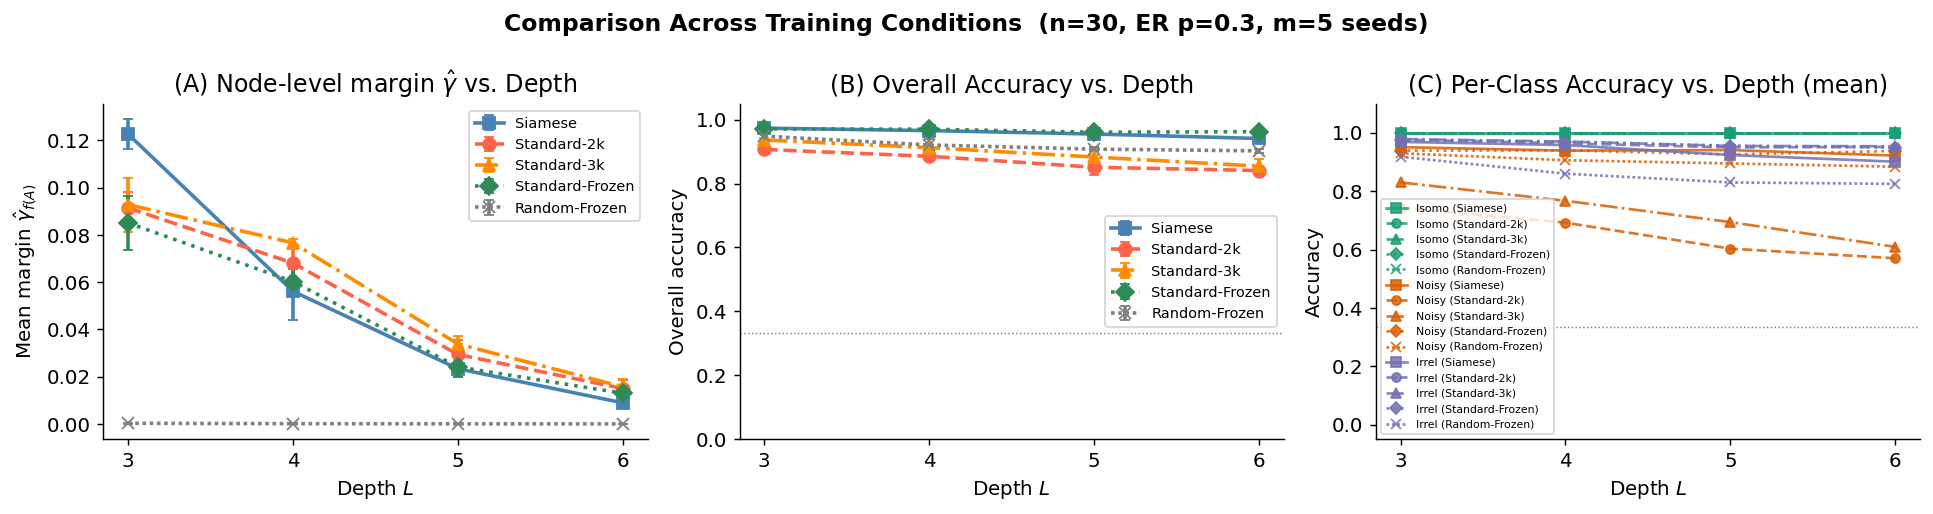

In [10]:
Ls = DEPTH_VALUES

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(
    f'Comparison Across Training Conditions  (n={N_NODES}, ER p={ER_PROB}, m={len(SEEDS)} seeds)',
    fontsize=13, fontweight='bold'
)

# ── (A) γ vs depth ────────────────────────────────────────────────────────────
ax = axes[0]
for cond in CONDITIONS:
    st    = COND_STYLE[cond]
    means = [results[cond][L]['gamma_mean'] for L in Ls]
    stds  = [results[cond][L]['gamma_std']  for L in Ls]
    ax.errorbar(Ls, means, yerr=stds, marker=st['marker'], ls=st['ls'], color=st['color'],
                linewidth=2, markersize=7, capsize=3, label=cond)
ax.set_xlabel('Depth $L$'); ax.set_ylabel('Mean margin $\\hat{\\gamma}_{f(A)}$')
ax.set_title('(A) Node-level margin $\\hat{\\gamma}$ vs. Depth')
ax.set_xticks(Ls); ax.legend(fontsize=8)

# ── (B) Overall accuracy vs depth ────────────────────────────────────────────
ax = axes[1]
for cond in CONDITIONS:
    st    = COND_STYLE[cond]
    means = [results[cond][L]['acc_mean'] for L in Ls]
    stds  = [results[cond][L]['acc_std']  for L in Ls]
    ax.errorbar(Ls, means, yerr=stds, marker=st['marker'], ls=st['ls'], color=st['color'],
                linewidth=2, markersize=7, capsize=3, label=cond)
ax.axhline(1/3, color='grey', linestyle=':', linewidth=0.8)
ax.set_xlabel('Depth $L$'); ax.set_ylabel('Overall accuracy')
ax.set_title('(B) Overall Accuracy vs. Depth')
ax.set_xticks(Ls); ax.set_ylim(0, 1.05); ax.legend(fontsize=8)

# ── (C) Per-class accuracy vs depth ──────────────────────────────────────────
ax = axes[2]
cls_colors = ['#1b9e77', '#d95f02', '#7570b3']
for c, (cname, ccol) in enumerate(zip(CLASS_NAMES, cls_colors)):
    for cond in CONDITIONS:
        st   = COND_STYLE[cond]
        vals = [results[cond][L]['per_class_mean'][c] for L in Ls]
        ax.plot(Ls, vals, marker=st['marker'], ls=st['ls'], color=ccol,
                linewidth=1.5, markersize=5, alpha=0.85,
                label=f'{cname[:5]} ({cond})')
ax.axhline(1/3, color='grey', linestyle=':', linewidth=0.8)
ax.set_xlabel('Depth $L$'); ax.set_ylabel('Accuracy')
ax.set_title('(C) Per-Class Accuracy vs. Depth (mean)')
ax.set_xticks(Ls); ax.set_ylim(-0.05, 1.1); ax.legend(fontsize=6, ncol=1)

plt.tight_layout()
plt.savefig('comparison_acc_gamma_vs_depth.pdf', bbox_inches='tight')
plt.savefig('comparison_acc_gamma_vs_depth.png', bbox_inches='tight', dpi=150)
plt.show()


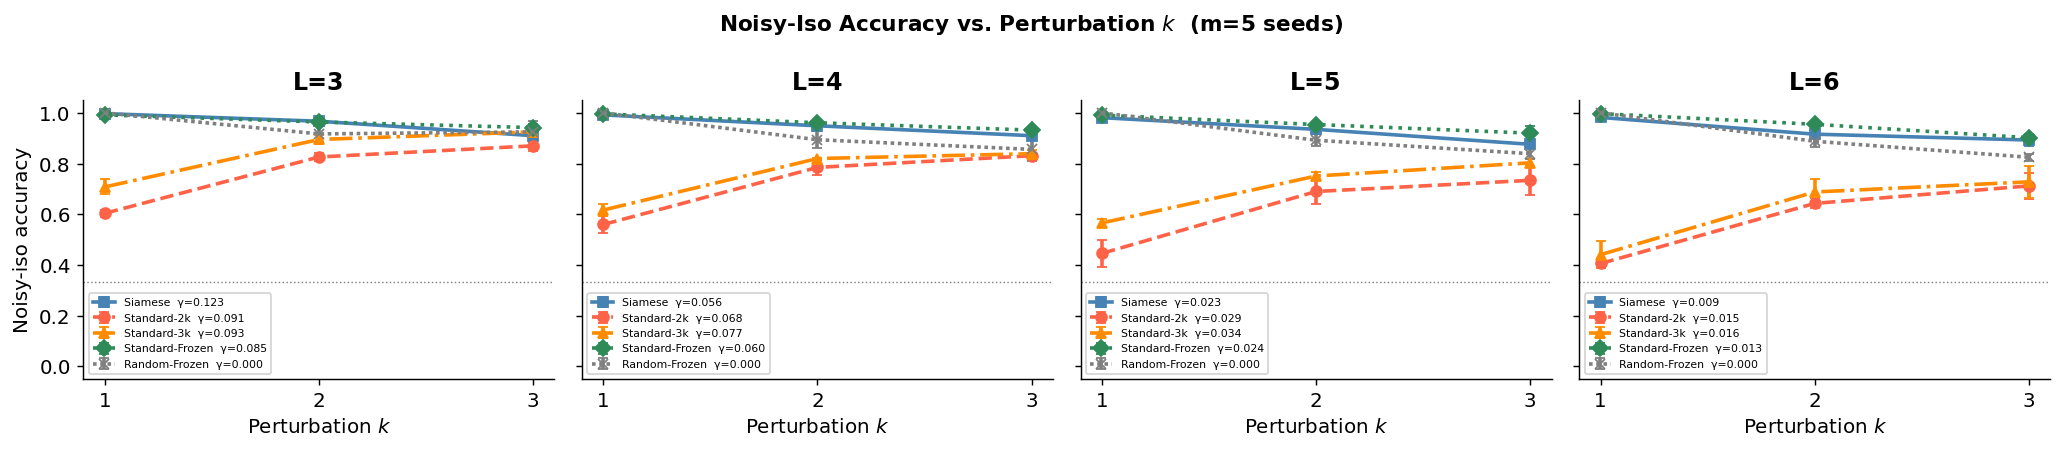

In [11]:
# ── Noisy-iso accuracy vs k, one subplot per depth ────────────────────────────
fig, axes = plt.subplots(1, len(DEPTH_VALUES), figsize=(16, 3.5), sharey=True)
fig.suptitle(
    f'Noisy-Iso Accuracy vs. Perturbation $k$  (m={len(SEEDS)} seeds)',
    fontsize=12, fontweight='bold'
)

k_vals = sorted(pyg_by_k.keys())
for ax, L in zip(axes, DEPTH_VALUES):
    for cond in CONDITIONS:
        st = COND_STYLE[cond]
        m  = results[cond][L]['acc_vs_k_mean']
        s  = results[cond][L]['acc_vs_k_std']
        ax.errorbar(k_vals, [m[k] for k in k_vals], yerr=[s[k] for k in k_vals],
                    marker=st['marker'], ls=st['ls'], color=st['color'],
                    linewidth=2, markersize=6, capsize=3,
                    label=f"{cond}  γ={results[cond][L]['gamma_mean']:.3f}")
    ax.axhline(1/3, color='grey', linestyle=':', linewidth=0.8)
    ax.set_title(f'L={L}', fontweight='bold')
    ax.set_xlabel('Perturbation $k$')
    ax.set_xticks(k_vals)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=6)

axes[0].set_ylabel('Noisy-iso accuracy')

plt.tight_layout()
plt.savefig('comparison_noisy_acc_vs_k.pdf', bbox_inches='tight')
plt.savefig('comparison_noisy_acc_vs_k.png', bbox_inches='tight', dpi=150)
plt.show()


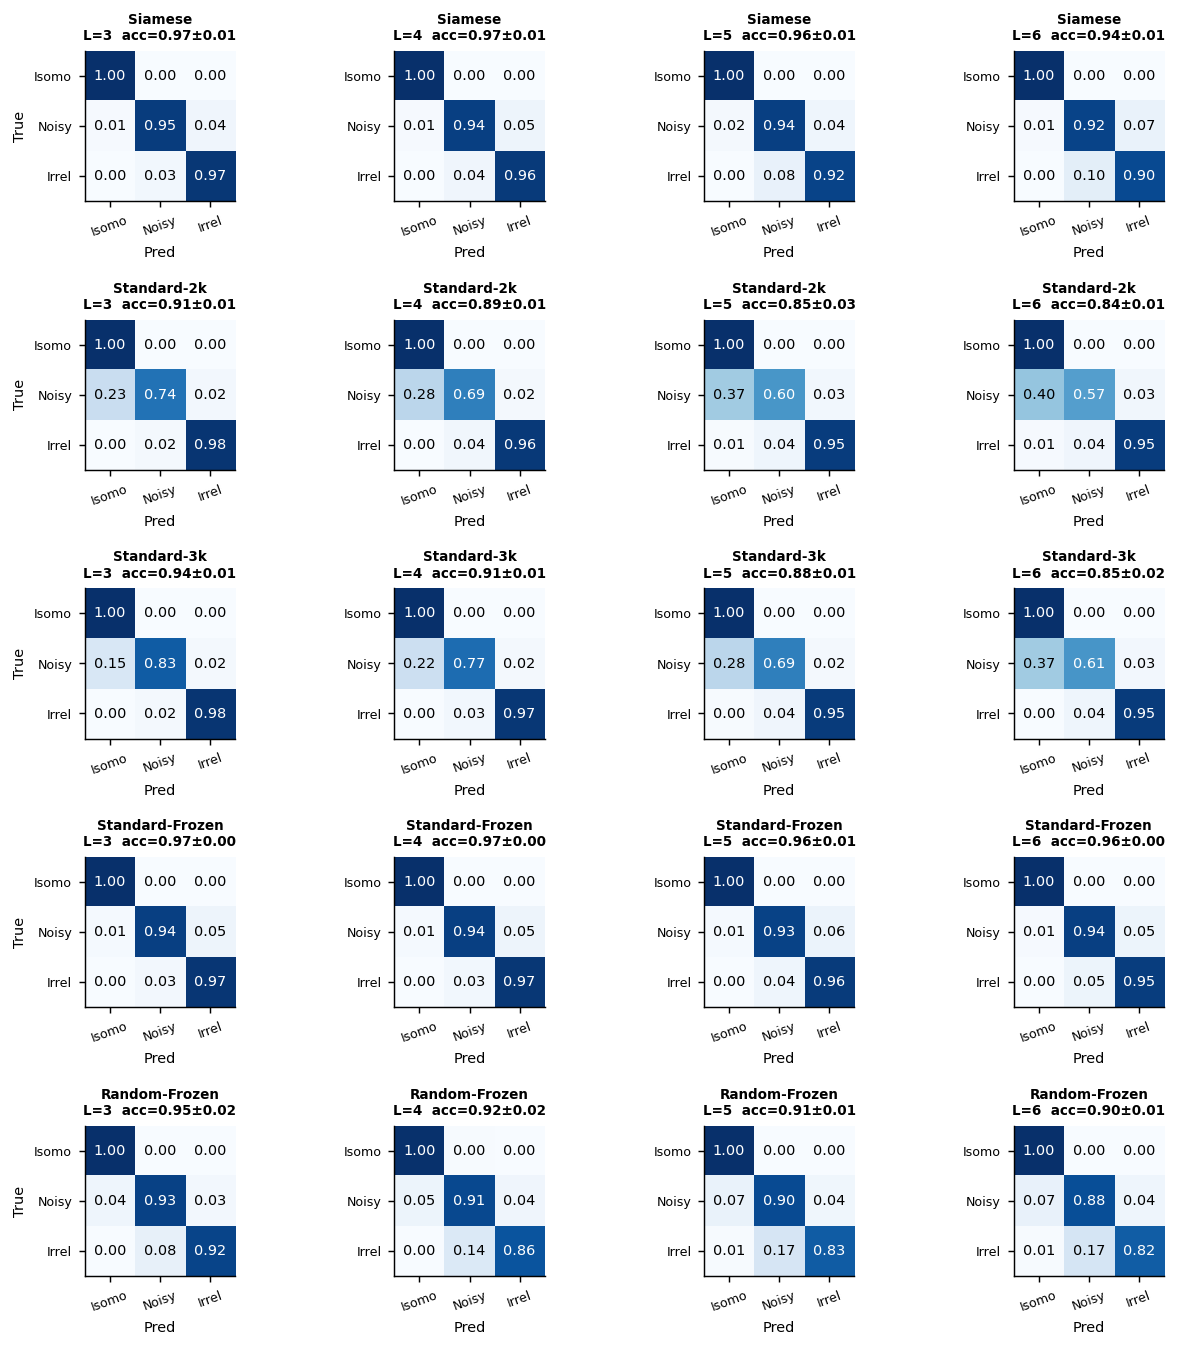

In [12]:
# ── Confusion matrices: one row per condition, one column per depth ──────────
fig, axes = plt.subplots(len(CONDITIONS), len(DEPTH_VALUES), figsize=(10, 10.5))
short = [n[:5] for n in CLASS_NAMES]

for row, cond in enumerate(CONDITIONS):
    for col, L in enumerate(DEPTH_VALUES):
        ax          = axes[row][col]
        r           = results[cond][L]
        preds, lbls = r['preds_all'], r['labels_all']
        cm_arr = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
        for p, l in zip(preds, lbls): cm_arr[l, p] += 1
        cm_norm = cm_arr.astype(float) / cm_arr.sum(1, keepdims=True).clip(min=1)
        im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
        ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
        ax.set_xticklabels(short, rotation=20, fontsize=7)
        ax.set_yticklabels(short, fontsize=7)
        for i in range(N_CLASSES):
            for j in range(N_CLASSES):
                ax.text(j, i, f'{cm_norm[i,j]:.2f}', ha='center', va='center',
                        fontsize=8, color='white' if cm_norm[i,j] > 0.55 else 'black')
        ax.set_title(f'{cond}\nL={L}  acc={r["acc_mean"]:.2f}±{r["acc_std"]:.2f}',
                     fontsize=7.5, fontweight='bold')
        if col == 0: ax.set_ylabel('True', fontsize=8)
        ax.set_xlabel('Pred', fontsize=8)

plt.tight_layout()
plt.savefig('comparison_confusion.pdf', bbox_inches='tight')
plt.savefig('comparison_confusion.png', bbox_inches='tight', dpi=150)
plt.show()


## 9. Summary Table


In [13]:
hdr = (f"{'Condition':<16} {'L':>2}  {'gamma (mean+-std)':>18}  {'Overall (mean+-std)':>20}  "
       f"{'Iso':>12}  {'Noisy':>12}  {'Irr':>12}  "
       + '  '.join(f'k={k}' for k in sorted(pyg_by_k.keys())))
print(hdr); print('─' * len(hdr))

for cond in CONDITIONS:
    for L in DEPTH_VALUES:
        r  = results[cond][L]
        pc_m, pc_s   = r['per_class_mean'], r['per_class_std']
        avk_m, avk_s = r['acc_vs_k_mean'], r['acc_vs_k_std']
        kstr = '  '.join(f'{avk_m[k]:.2f}+-{avk_s[k]:.2f}' for k in sorted(avk_m.keys()))
        print(f"{cond:<16} {L:>2}  "
              f"{r['gamma_mean']:.4f}+-{r['gamma_std']:.4f}      "
              f"{r['acc_mean']:.3f}+-{r['acc_std']:.3f}         "
              f"{pc_m[0]:.2f}+-{pc_s[0]:.2f}  {pc_m[1]:.2f}+-{pc_s[1]:.2f}  {pc_m[2]:.2f}+-{pc_s[2]:.2f}  "
              f"{kstr}")
    print()


Condition         L   gamma (mean+-std)   Overall (mean+-std)           Iso         Noisy           Irr  k=1  k=2  k=3
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Siamese           3  0.1227+-0.0064      0.973+-0.006         1.00+-0.00  0.95+-0.01  0.97+-0.01  1.00+-0.00  0.97+-0.01  0.91+-0.02
Siamese           4  0.0561+-0.0122      0.966+-0.007         1.00+-0.00  0.94+-0.01  0.96+-0.01  0.99+-0.01  0.95+-0.00  0.91+-0.02
Siamese           5  0.0233+-0.0031      0.955+-0.006         1.00+-0.00  0.94+-0.01  0.92+-0.01  0.98+-0.01  0.93+-0.01  0.88+-0.01
Siamese           6  0.0089+-0.0016      0.941+-0.007         1.00+-0.00  0.92+-0.02  0.90+-0.01  0.98+-0.01  0.92+-0.01  0.89+-0.02

Standard-2k       3  0.0914+-0.0066      0.907+-0.008         1.00+-0.00  0.74+-0.02  0.98+-0.01  0.60+-0.01  0.83+-0.01  0.87+-0.02
Standard-2k       4  0.0681+-0.0069      0.885+-0.012         1.00+-0.00  0.69+-0.04  0.96+-0.01